## EDA Project - SwiftCart Retail Analysis

### Sprint-2

### 1. Import libraries and prepare the data

In [1]:
## Importing libraries
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

In [2]:
import warnings 
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("swiftcart_cleaned.csv")
df

,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,171-1029312-3038738,1029312.0,Women,37,Adult,2022-12-04,Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376.0,MOHALI,PUNJAB,140301,IN,False
1,405-2183842-2225946,2183842.0,Women,29,Adult,2022-12-04,Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449.0,GURUGRAM,HARYANA,122002,IN,False
2,171-1641533-8921966,1641533.0,Women,67,Senior,2022-12-04,Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453.0,KOLKATA,WEST BENGAL,700029,IN,False
3,404-7490807-6300351,7490807.0,Women,20,Adult,2022-12-04,Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729.0,THANJAVUR,TAMIL NADU,613007,IN,False
4,403-9293516-4577154,9293516.0,Women,62,Senior,2022-12-04,Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544.0,GURUGRAM,HARYANA,122001,IN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31019,405-4724097-1016369,4724097.0,Men,60,Senior,2022-01-06,Jan,Delivered,Flipkart,J0083-KR-XL,kurta,XL,1,INR,565.0,PUNE,MAHARASHTRA,412307,IN,False
31020,405-4724097-1016369,4724097.0,Men,37,Adult,2022-01-06,Jan,Delivered,Myntra,J0010-LCD-S,Set,S,1,INR,939.0,BENGALURU,KARNATAKA,560061,IN,False
31021,408-3572295-5992330,3572295.0,Men,29,Adult,2022-01-06,Jan,Delivered,Amazon,SET398-KR-PP-L,Set,L,1,INR,1115.0,PITHORAGARH,UTTARAKHAND,262501,IN,False
31022,405-1423498-9705162,1423498.0,Men,46,Adult,2022-01-06,Jan,Delivered,Amazon,JNE3568-KR-M,kurta,M,1,INR,399.0,DHULE,MAHARASHTRA,424006,IN,False


In [4]:
sns.set_theme(style="whitegrid")

In [5]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (31024, 20)


,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,171-1029312-3038738,1029312.0,Women,37,Adult,2022-12-04,Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376.0,MOHALI,PUNJAB,140301,IN,False
1,405-2183842-2225946,2183842.0,Women,29,Adult,2022-12-04,Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449.0,GURUGRAM,HARYANA,122002,IN,False
2,171-1641533-8921966,1641533.0,Women,67,Senior,2022-12-04,Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453.0,KOLKATA,WEST BENGAL,700029,IN,False
3,404-7490807-6300351,7490807.0,Women,20,Adult,2022-12-04,Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729.0,THANJAVUR,TAMIL NADU,613007,IN,False
4,403-9293516-4577154,9293516.0,Women,62,Senior,2022-12-04,Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544.0,GURUGRAM,HARYANA,122001,IN,False


### 2.Descriptive statistical analysis

In [6]:
df[['Age', 'Qty', 'Amount']].describe()

,Age,Qty,Amount
count,31024.000000,31024.000000,31024.000000
mean,39.394759,1.011958,682.162261
std,14.849749,0.292078,268.599470
min,18.000000,1.000000,229.000000
25%,28.000000,1.000000,486.000000
50%,37.000000,1.000000,646.000000
75%,47.000000,1.000000,794.000000
max,78.000000,20.000000,3036.000000


In [7]:
for col in ['Age', 'Qty', 'Amount']:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().tolist())
    print("Variance:", df[col].var())
    print("Standard deviation:", df[col].std())
    print("Skewness:", df[col].skew())


 Age
Mean: 39.39475889633832
Median: 37.0
Mode: [37]
Variance: 220.51504973073256
Standard deviation: 14.849749147064154
Skewness: 0.7603258912628337

 Qty
Mean: 1.0119584837545126
Median: 1.0
Mode: [1]
Variance: 0.0853097186773137
Standard deviation: 0.2920782749149852
Skewness: 43.71024312329006

 Amount
Mean: 682.1622614749871
Median: 646.0
Mode: [399.0]
Variance: 72145.67544002298
Standard deviation: 268.5994702899151
Skewness: 1.0528545562509288


### Customer analysis

#### 3.1 Gender distribution

Gender
Women      20794
Men         9155
Unknown     1075
Name: count, dtype: int64


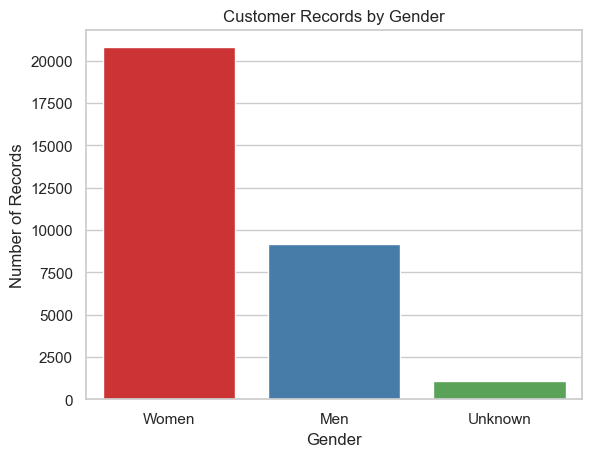

In [54]:
print(df['Gender'].value_counts())

sns.countplot(data=df, x='Gender', palette='Set1')
plt.title('Customer Records by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Records')
plt.show()

#### 3.2 Age-group distribution

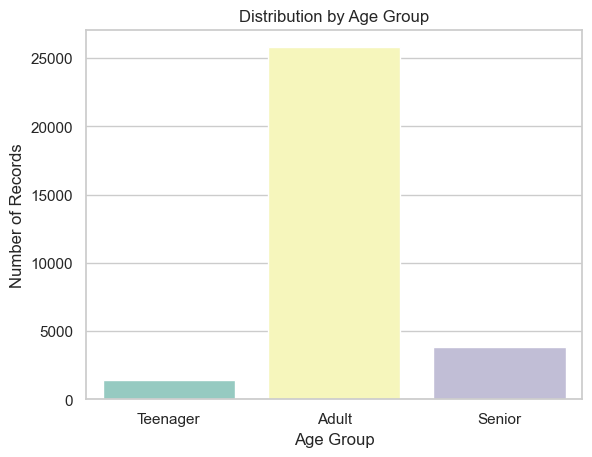

In [53]:
sns.countplot(data=df, x='Age Group', order=['Teenager', 'Adult', 'Senior'], palette='Set3')
plt.title('Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Records')
plt.show()

#### 3.3 Customer purchasing behaviour

In [10]:
print("Unique customers:", df['Cust ID'].nunique())

customer_orders = df.groupby('Cust ID', dropna=True)['Order ID'].nunique()
print(customer_orders.sort_values(ascending=False).head(10))

Unique customers: 28375
Cust ID
49070840.0    7
unknown       4
88377930.0    3
73648275.0    3
49098850.0    2
6529033.0     2
925784.0      2
5784045.0     2
5107060.0     2
908483.0      2
Name: Order ID, dtype: int64


### 4.Product analysis

#### 4.1 Category distribution

Category
Set              12384
kurta            10433
Western Dress     4065
Top               2191
Saree             1380
Ethnic Dress       264
Blouse             229
Bottom              78
Name: count, dtype: int64


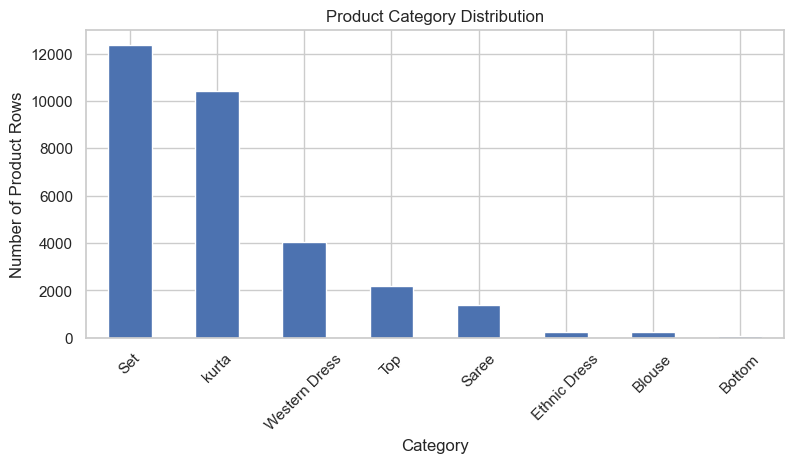

In [56]:
category_counts = df['Category'].value_counts()

print(category_counts)

category_counts.plot(kind='bar', figsize=(9, 4))
plt.title('Product Category Distribution')
plt.xlabel('Category')
plt.ylabel('Number of Product Rows')
plt.xticks(rotation=45)
plt.show()

#### 4.2 Sales amount by category

Category
Set              10502211.0
kurta             4953662.0
Western Dress     3147928.0
Top               1185182.0
Saree             1010471.0
Ethnic Dress       195256.0
Blouse             140888.0
Bottom              27804.0
Name: Amount, dtype: float64


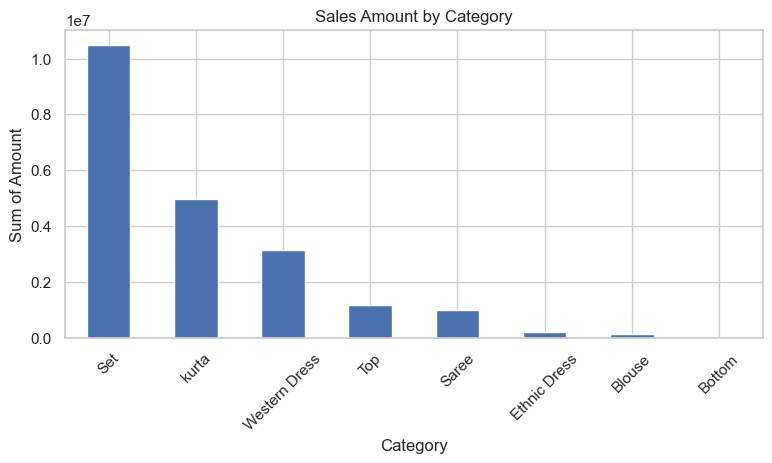

In [12]:
category_sales = df.groupby('Category')['Amount'].sum().sort_values(ascending=False)

print(category_sales)

category_sales.plot(kind='bar', figsize=(9, 4))
plt.title('Sales Amount by Category')
plt.xlabel('Category')
plt.ylabel('Sum of Amount')
plt.xticks(rotation=45)
plt.show()

#### 4.3 Size distribution

Size
M       5481
L       5138
XL      4434
S       4173
XXL     4064
3XL     3345
XS      2499
Free    1408
6XL      208
5XL      161
4XL      113
Name: count, dtype: int64


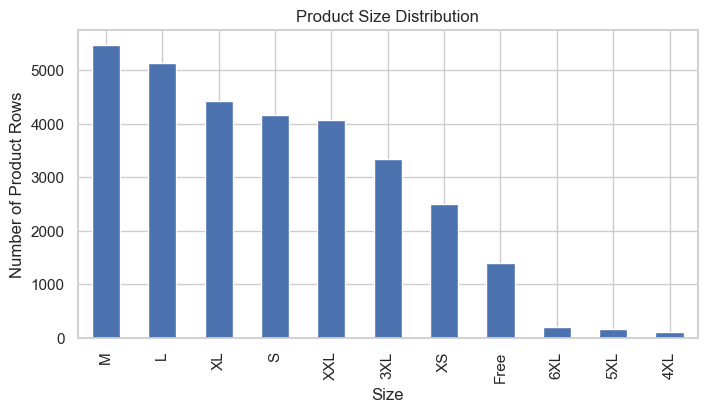

In [13]:
size_counts = df['Size'].value_counts()

print(size_counts)

size_counts.plot(kind='bar', figsize=(8, 4))
plt.title('Product Size Distribution')
plt.xlabel('Size')
plt.ylabel('Number of Product Rows')
plt.show()

### 5. Sales analysis

#### 5.1 Overall sales summary

In [14]:
print("Total recorded Amount:", df['Amount'].sum())
print("Average Amount:", df['Amount'].mean())
print("Median Amount:", df['Amount'].median())
print("Minimum Amount:", df['Amount'].min())
print("Maximum Amount:", df['Amount'].max())

Total recorded Amount: 21163402.0
Average Amount: 682.1622614749871
Median Amount: 646.0
Minimum Amount: 229.0
Maximum Amount: 3036.0


#### 5.2 Sales distribution

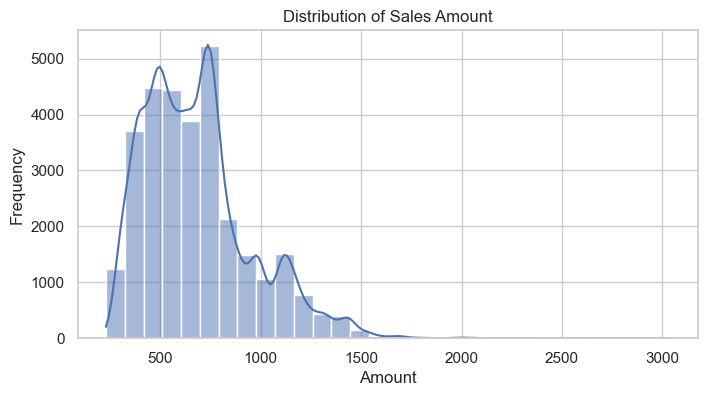

In [59]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Amount', bins=30, kde=True)
plt.title('Distribution of Sales Amount')
plt.xlabel('Amount')
plt.ylabel('Frequency')
plt.show()

#### 5.3 Sales by channel

Channel
Amazon      7514511.0
Myntra      4937855.0
Flipkart    4571751.0
Ajio        1331132.0
Nalli       1013805.0
Meesho       927606.0
Others       866742.0
Name: Amount, dtype: float64


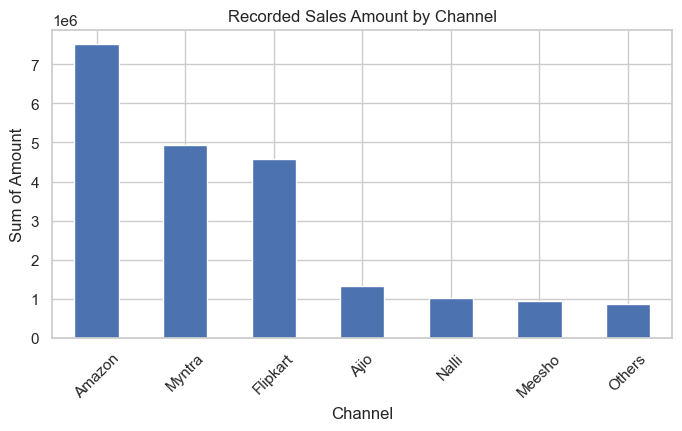

In [16]:
channel_sales = df.groupby('Channel')['Amount'].sum().sort_values(ascending=False)

print(channel_sales)

channel_sales.plot(kind='bar', figsize=(8, 4))
plt.title('Recorded Sales Amount by Channel')
plt.xlabel('Channel')
plt.ylabel('Sum of Amount')
plt.xticks(rotation=45)
plt.show()

### 6. Order analysis

#### 6.1 Order status distribution

Status
Delivered    28618
Returned      1045
Cancelled      844
Refunded       517
Name: count, dtype: int64


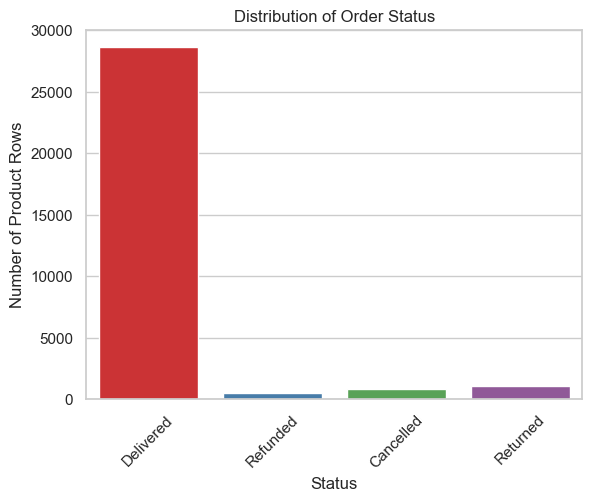

In [62]:
print(df['Status'].value_counts(dropna=False))

sns.countplot(data=df, x='Status',palette='Set1')
plt.title('Distribution of Order Status')
plt.xlabel('Status')
plt.ylabel('Number of Product Rows')
plt.xticks(rotation=45)
plt.show()

#### 6.2 Quantity distribution

Qty
1     30853
2       130
3        19
4         6
5         1
8         3
10        1
11        1
12        1
13        3
15        3
17        1
18        1
20        1
Name: count, dtype: int64


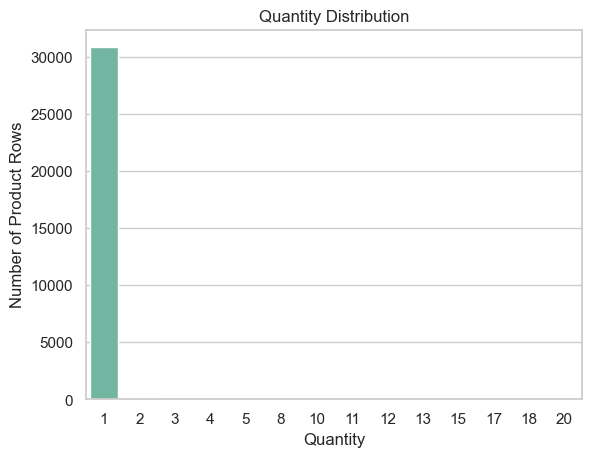

In [64]:
print(df['Qty'].value_counts().sort_index())

sns.countplot(data=df, x='Qty',palette='Set2')
plt.title('Quantity Distribution')
plt.xlabel('Quantity')
plt.ylabel('Number of Product Rows')
plt.show()

#### 6.3 Distinct Order IDs by status

In [19]:
status_orders = df.groupby('Status')['Order ID'].nunique()
print(status_orders)

Status
Cancelled      800
Delivered    25494
Refunded       480
Returned       968
Name: Order ID, dtype: int64


### 7. Time-based analysis

#### 7.1 Monthly recorded sales

Month
Jan    1779538.0
Feb    1847889.0
Mar    1897253.0
Apr    1806318.0
May    1767870.0
Jun    1722520.0
Jul    1741423.0
Aug    1777840.0
Sep    1664457.0
Oct    1643788.0
Nov    1591621.0
Dec    1592933.0
Name: Amount, dtype: float64


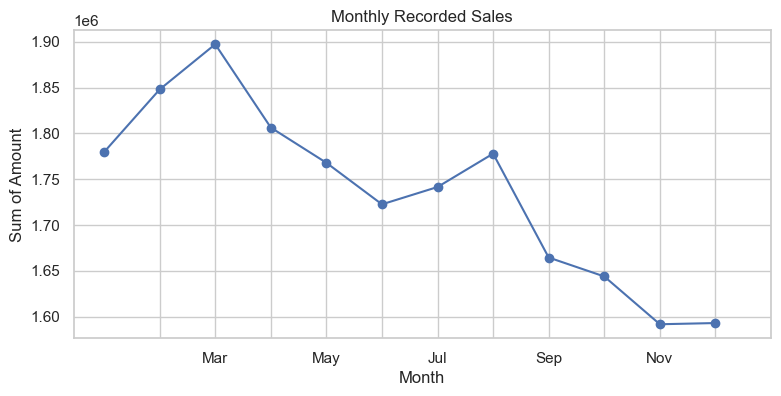

In [22]:
monthly_sales = df.groupby('Month')['Amount'].sum()
monthly_sales = monthly_sales.reindex([
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
])
print(monthly_sales)

monthly_sales.plot(kind='line', marker='o', figsize=(9, 4))

plt.title('Monthly Recorded Sales')
plt.xlabel('Month')
plt.ylabel('Sum of Amount')
plt.xticks(range(1, 13))
plt.show()

#### 8. Group-based analysis

#### Sales by category and gender

In [26]:
df.groupby(['Category', 'Gender'])['Amount'].agg(
    ['sum', 'mean', 'count']
).round(2)

sum    mean  count
Category      Gender                           
Blouse        Men         5331.0  761.57      7
              Unknown     4447.0  741.17      6
              Women     131110.0  606.99    216
Bottom        Men        15579.0  354.07     44
              Unknown      733.0  366.50      2
              Women      11492.0  359.12     32
Ethnic Dress  Men       127298.0  748.81    170
              Unknown     5213.0  744.71      7
              Women      62745.0  721.21     87
Saree         Men       209352.0  742.38    282
              Unknown    31921.0  760.02     42
              Women     769198.0  728.41   1056
Set           Men      4157827.0  842.35   4936
              Unknown   405804.0  891.88    455
              Women    5938580.0  849.22   6993
Top           Men        26284.0  536.41     49
              Unknown    43727.0  546.59     80
              Women    1115171.0  540.82   2062
Western Dress Men      2707089.0  775.00   3493
              Unknown   105184.0  796.85    132
              Women     335655.0  762.85    440
kurta         Men        82530.0  474.31    174
              Unknown   168208.0  479.23    351
              Women    4702924.0  474.66   9908

#### Sales by shipping state

ship-state
MAHARASHTRA       2990221.0
KARNATAKA         2644636.0
UTTAR PRADESH     2103293.0
TELANGANA         1711680.0
TAMIL NADU        1675558.0
DELHI             1273802.0
KERALA            1007709.0
WEST BENGAL        921486.0
ANDHRA PRADESH     917858.0
HARYANA            813320.0
Name: Amount, dtype: float64


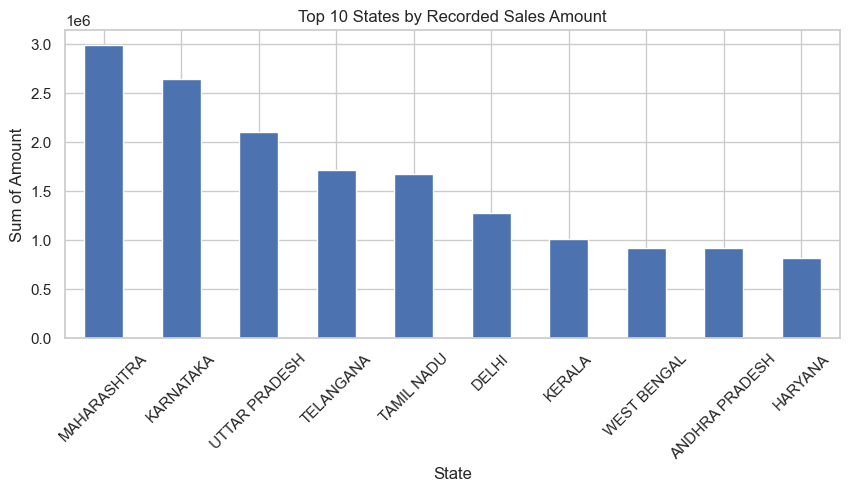

In [66]:
state_sales = df.groupby('ship-state')['Amount'].sum().sort_values(ascending=False)

print(state_sales.head(10))

state_sales.head(10).plot(kind='bar', figsize=(10, 4))
plt.title('Top 10 States by Recorded Sales Amount')
plt.xlabel('State')
plt.ylabel('Sum of Amount')
plt.xticks(rotation=45)
plt.show()

#### Channel comparison

In [28]:
df.groupby('Channel').agg(
    Total_Amount=('Amount', 'sum'),
    Average_Amount=('Amount', 'mean'),
    Product_Rows=('Amount', 'count'),
    Unique_Orders=('Order ID', 'nunique')
).sort_values('Total_Amount', ascending=False)

,Total_Amount,Average_Amount,Product_Rows,Unique_Orders
Channel,,,,
Amazon,7514511.0,682.702916,11007,10219
Myntra,4937855.0,681.365393,7247,6849
Flipkart,4571751.0,682.350896,6700,6330
Ajio,1331132.0,689.705699,1930,1854
Nalli,1013805.0,684.078947,1482,1418
Meesho,927606.0,663.523605,1398,1344
Others,866742.0,687.890476,1260,1216


### 9. Pivot table analysis

#### 9.1 Category versus channel

In [29]:
pd.pivot_table(
    df,
    index='Category',
    columns='Channel',
    values='Amount',
    aggfunc='sum',
    fill_value=0
)

Channel,Ajio,Amazon,Flipkart,Meesho,Myntra,Nalli,Others
Category,,,,,,,
Blouse,46952.0,4334.0,1865.0,27776.0,58277.0,339.0,1345.0
Bottom,3193.0,6153.0,5151.0,660.0,10229.0,1425.0,993.0
Ethnic Dress,16266.0,74919.0,39947.0,7655.0,42517.0,9579.0,4373.0
Saree,6960.0,401371.0,262378.0,9606.0,230276.0,54688.0,45192.0
Set,680195.0,3750699.0,2285301.0,455135.0,2397356.0,494901.0,438624.0
Top,86142.0,408157.0,265862.0,50674.0,278565.0,54145.0,41637.0
Western Dress,193972.0,1121472.0,663511.0,127247.0,752061.0,159985.0,129680.0
kurta,297452.0,1747406.0,1047736.0,248853.0,1168574.0,238743.0,204898.0


#### 9.2 State versus category

In [30]:
pd.pivot_table(
    df,
    index='ship-state',
    columns='Category',
    values='Amount',
    aggfunc='sum',
    fill_value=0
)

Category,Blouse,Bottom,Ethnic Dress,Saree,Set,Top,Western Dress,kurta
ship-state,,,,,,,,
ANDAMAN & NICOBAR,0.0,0.0,0.0,2841.0,32300.0,1171.0,6915.0,8743.0
ANDHRA PRADESH,4260.0,1709.0,8051.0,28404.0,440528.0,25117.0,157455.0,252334.0
ARUNACHAL PRADESH,0.0,0.0,0.0,3942.0,18429.0,8105.0,3294.0,3070.0
ASSAM,2839.0,1095.0,2020.0,10318.0,182105.0,15779.0,41222.0,71045.0
BIHAR,20077.0,1476.0,373.0,97195.0,202742.0,10951.0,46782.0,67235.0
CHANDIGARH,0.0,0.0,0.0,1301.0,33314.0,7479.0,7208.0,13757.0
CHHATTISGARH,2118.0,0.0,2246.0,2731.0,115265.0,3050.0,15622.0,33499.0
DADRA AND NAGAR,0.0,0.0,0.0,801.0,9836.0,693.0,1542.0,2108.0
DELHI,2387.0,345.0,7549.0,54718.0,727746.0,106753.0,128470.0,245834.0


#### 9.3 Age group versus gender

In [32]:
pd.pivot_table(
    df,
    index='Age Group',
    columns='Gender',
    values='Amount',
    aggfunc='mean'
)

Gender,Men,Unknown,Women
Age Group,,,
Adult,802.507803,708.577851,628.027630
Senior,790.465137,740.972222,633.677557
Teenager,797.408060,708.890909,620.876955


### 10. Crosstab analysis

#### 10.1 Category versus size

In [33]:
pd.crosstab(df['Category'], df['Size'])

Size,3XL,4XL,5XL,6XL,Free,L,M,S,XL,XS,XXL
Category,,,,,,,,,,,
Blouse,0,0,0,0,28,53,43,37,33,1,34
Bottom,13,0,0,0,0,13,7,11,13,4,17
Ethnic Dress,39,0,0,0,0,50,47,39,40,18,31
Saree,0,0,0,0,1380,0,0,0,0,0,0
Set,1326,11,15,16,0,2017,2476,1977,1744,1287,1515
Top,223,0,0,0,0,356,376,285,374,230,347
Western Dress,537,0,0,0,0,780,713,545,585,344,561
kurta,1207,102,146,192,0,1869,1819,1279,1645,615,1559


#### 10.2 Channel versus status

In [34]:
pd.crosstab(df['Channel'], df['Status'])

Status,Cancelled,Delivered,Refunded,Returned
Channel,,,,
Ajio,54,1792,24,60
Amazon,308,10115,201,383
Flipkart,188,6170,113,229
Meesho,38,1288,25,47
Myntra,188,6706,116,237
Nalli,34,1373,22,53
Others,34,1174,16,36


#### 10.3 Gender versus age group

In [35]:
pd.crosstab(df['Gender'], df['Age Group'])

Age Group,Adult,Senior,Teenager
Gender,,,
Men,7625,1133,397
Unknown,912,108,55
Women,17264,2571,959


In [73]:
status_percentage = pd.crosstab(
    df['Channel'],
    df['Status'],
    normalize='index'
) * 100

print(status_percentage.round(2))

Status    Cancelled  Delivered  Refunded  Returned
Channel                                           
Ajio           2.80      92.85      1.24      3.11
Amazon         2.80      91.90      1.83      3.48
Flipkart       2.81      92.09      1.69      3.42
Meesho         2.72      92.13      1.79      3.36
Myntra         2.59      92.53      1.60      3.27
Nalli          2.29      92.65      1.48      3.58
Others         2.70      93.17      1.27      2.86


### 11. Relationship analysis

#### 11.1 Numerical correlations

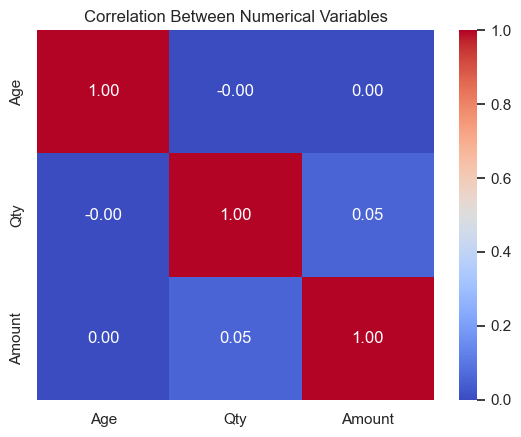

In [36]:
corr = df[['Age', 'Qty', 'Amount']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Numerical Variables')
plt.show()

#### 11.2 Age versus amount

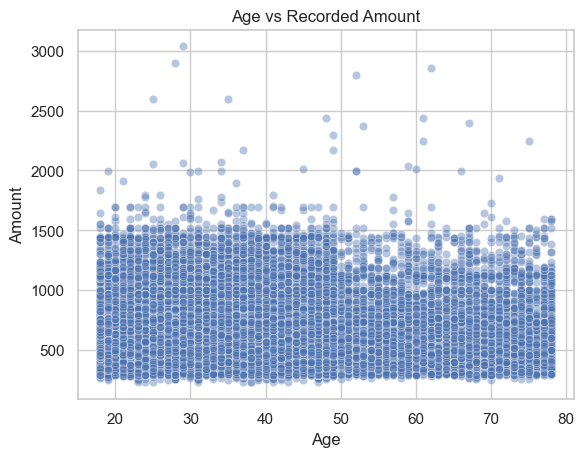

In [69]:
sns.scatterplot(data=df, x='Age', y='Amount', alpha=0.4)
plt.title('Age vs Recorded Amount')
plt.show()

#### 11.3 Amount by category

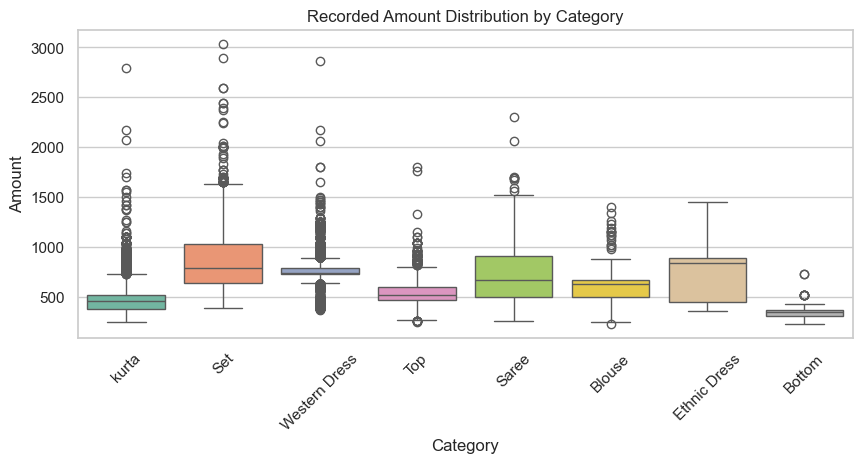

In [70]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='Category', y='Amount', palette='Set2')
plt.title('Recorded Amount Distribution by Category')
plt.xticks(rotation=45)
plt.show()

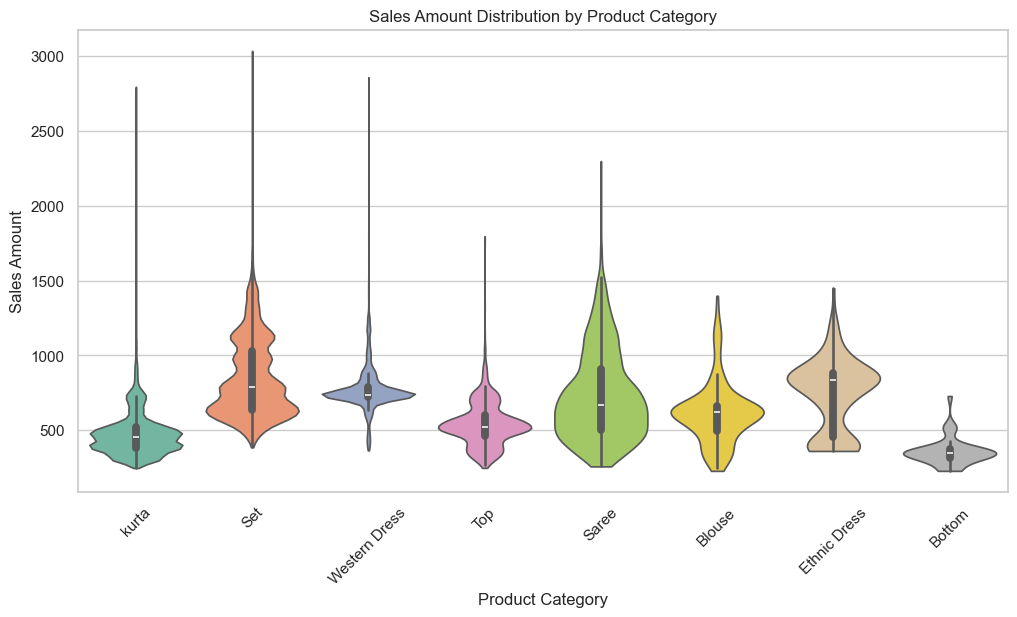

In [45]:
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x='Category',
    y='Amount',
    palette='Set2',
    cut=0
)

plt.title('Sales Amount Distribution by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Sales Amount')
plt.xticks(rotation=45)
plt.show()

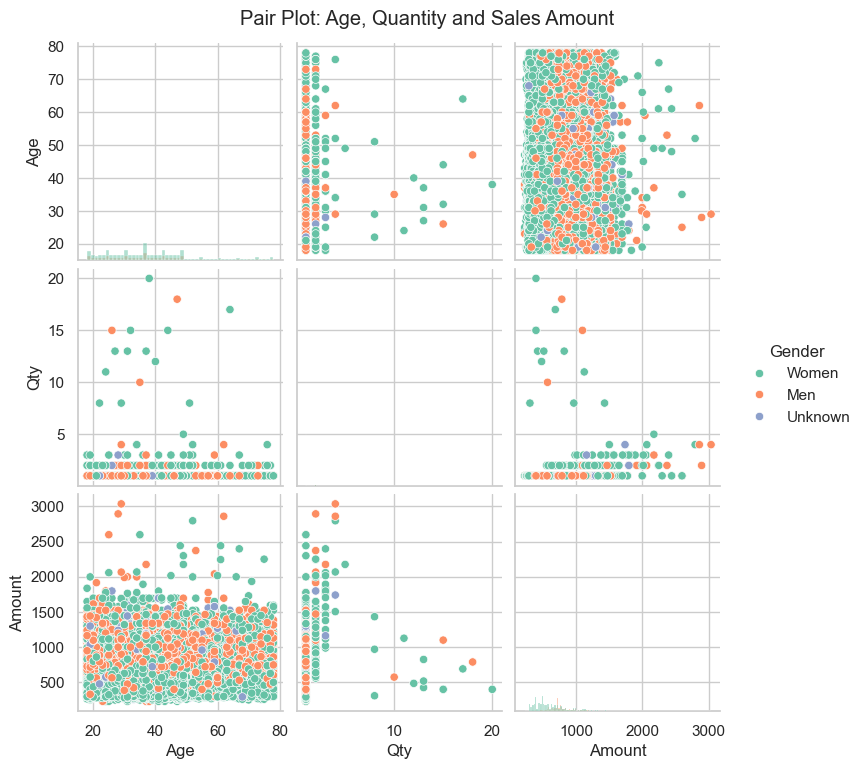

In [48]:
sns.pairplot(
    data=df,
    vars=['Age', 'Qty', 'Amount'],
    hue='Gender',
    palette='Set2',
    diag_kind='hist'
)

plt.suptitle('Pair Plot: Age, Quantity and Sales Amount', y=1.02)
plt.show()

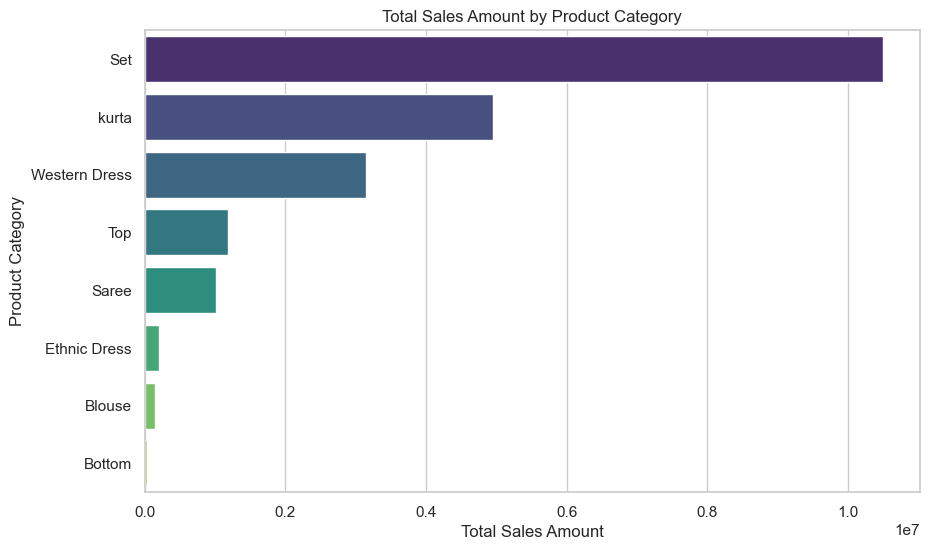

In [72]:
category_sales = df.groupby('Category')['Amount'].sum().
    sort_values(
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index,
    hue=category_sales.index,
    palette='viridis',
    legend=False
)

plt.title('Total Sales Amount by Product Category')
plt.xlabel('Total Sales Amount')
plt.ylabel('Product Category')
plt.show()

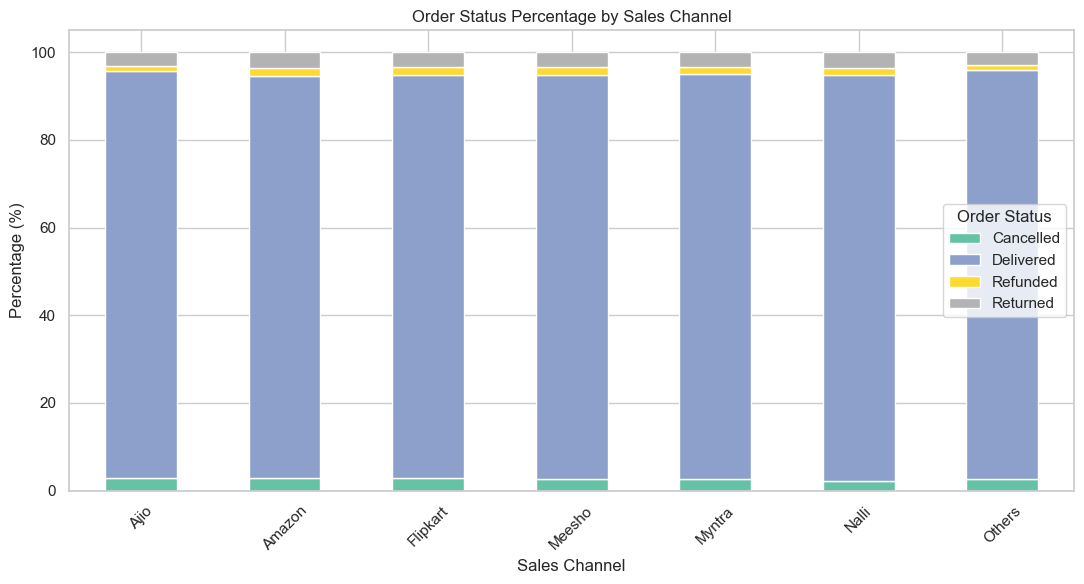

In [75]:
status_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6),
    colormap='Set2'
)

plt.title('Order Status Percentage by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Order Status')
plt.tight_layout()
plt.show()

### 12. Visual storytelling

### 1. Observation

- Set is the most frequent category, with 12,384 records.
- Kurta is the second most frequent, with 10,433 records.
- Western Dress ranks third, with 4,065 records.
- Bottom has the fewest records, with 78.

### Product Category Distribution

The category distribution shows that Sets and kurtas account for the largest number of product records, while Bottom has the fewest. This indicates that the dataset's product activity is concentrated in a few categories. SwiftCart should further analyze category-wise sales, quantities, inventory availability, and profitability to identify its strongest product categories and make informed inventory decisions.


### Observation: 
- Sets and Ethnic Dresses have the highest median prices (₹788–₹837), while Kurtas and Bottoms are priced lowest (₹345–₹457).
- Sets also show the highest outlier purchases, reaching above ₹3,000.
### Interpretation: 
- Kurtas serve as high-volume, affordable entry items, whereas Sets drive the core high-ticket revenue for the business.
#### Business Insight: 
- Promote Kurta-to-Set upsell bundles (e.g., "Add matching pants and dupatta for +₹300"), and stock more premium festival Sets priced above ₹1,800 to capture high-spending shoppers.

### Correlation Analysis of Customer Age, Quantity, and Sales Amount

**Observation:** The correlation between Age and Qty is approximately -0.00, while Age and Amount have a correlation of 0.00. The correlation between Qty and Amount is 0.05.

**Interpretation:** Customer age has almost no linear relationship with recorded quantity or sales amount. Quantity and sales amount have a very weak positive linear relationship.

**Business Insight:** Age alone may not be a useful indicator of purchase quantity or sales amount. Similarly, quantity alone has little linear association with the recorded sales amount in this dataset.

**Recommendation:** Investigate customer segments using age groups, product categories, order frequency, and sales amount. Check how `Amount` is calculated before drawing conclusions about quantity and spending.


### Category-wise Sales Analysis

**Observation:** Set records the highest total sales amount, followed by kurta and Western Dress. Bottom records the lowest total sales amount.

**Interpretation:** Recorded sales are concentrated in the Set category, which contributes substantially more than any other category.

**Business Insight:** Sets, kurtas, and Western Dresses are important categories to investigate for sales performance. However, total sales amount alone does not establish profitability or customer demand.

**Recommendation:** Review inventory availability, profit margins, discounts, and returns for the leading categories. Investigate the low recorded sales amount for Bottom before making decisions about stocking or promotion.


### Sales Channel Performance Analysis

**Observation:** Amazon recorded the highest total sales amount (7,514,511), followed by Myntra (4,937,855) and Flipkart (4,571,751). Amazon also had the highest number of product records and unique orders.

**Interpretation:** Amazon contributes the largest share of recorded sales among the listed channels. Myntra and Flipkart are the next largest contributors.

**Business Insight:** Amazon is the strongest channel by total recorded sales and order count in this dataset. However, these figures do not reveal channel profitability or marketing efficiency.

**Recommendation:** Investigate what contributes to Amazon's performance, compare commission fees and profit margins across channels, and explore ways to improve performance on smaller channels.


### Order Status Analysis by Sales Channel

**Observation:** Delivered is the most frequent status across all channels. Amazon has the highest number of records in every status category, including Delivered, Cancelled, Refunded, and Returned.

**Interpretation:** Amazon has the largest volume of order-status records in this dataset. Its higher cancellation and return counts may partly reflect its larger overall volume.

**Business Insight:** Comparing raw counts is not sufficient to determine which channel performs best in order fulfilment. Status percentages are needed for a fairer comparison.

**Recommendation:** Calculate cancellation, refund, and return percentages for each channel. Investigate channels with higher rates and identify opportunities to improve order fulfilment and customer experience.


### 13.1 Customer Insights

**Observation:** The dataset contains customer age information, which can be grouped into Teenager, Adult, and Senior segments. The correlation analysis shows almost no linear relationship between age and recorded sales amount.

**Business Insight:** Customer age alone may not be sufficient to explain differences in spending.

**Recommendations:** Analyze purchasing behavior across age groups and product categories.
Identify popular products for different customer segments.
Use customer purchase frequency and order history to develop targeted marketing campaigns.

### 13.2 Product Insights

**Observation:** Set has the highest number of product records (12,384), followed by kurta (10,433) and Western Dress (4,065). Bottom has the fewest records (78).

Set also generates the highest total recorded sales amount (10,502,211), followed by kurta (4,953,662) and Western Dress (3,147,928).

**Business Insight:** Sets and kurtas are major contributors to recorded sales in this dataset, while Bottom has a comparatively small presence.

**Recommendations:** Monitor inventory availability for Sets and kurtas.
Investigate whether low-record categories such as Bottom have limited demand, limited availability, or fewer listings.
Compare profit margins, discounts, returns, and quantities before making inventory decisions.

### 13.3 Sales Insights

**Observation:** Set contributes the highest total recorded sales amount among the product categories. The correlation between Qty and Amount is approximately 0.05, indicating a very weak positive linear relationship.

**Business Insight:** Recorded sales amounts differ substantially across product categories, while quantity alone has little linear association with Amount in this dataset.

**Recommendations:** Compare average sales amount, quantity sold, and total sales by category.
Investigate discounts and returns to understand sales performance more fully.
Confirm how the Amount column is defined before using it to estimate revenue or profitability.

### 13.4 Order Insights

**Observation:** Delivered is the most frequent status across all sales channels, accounting for approximately 92–93% of records. Cancellation, refund, and return percentages are relatively small but vary across channels.

**Business Insight:** Most records are marked Delivered, but cancellations, refunds, and returns still require monitoring.

**Recommendations:** Track cancellation, return, and refund rates regularly.
Investigate reasons for unsuccessful or reversed transactions.
Improve product descriptions, size information, and order fulfilment processes where the evidence indicates problems.

### 13.5 Sales Channel Insights

**Observation:** Amazon has the highest total recorded sales amount (7,514,511), followed by Myntra (4,937,855) and Flipkart (4,571,751). Amazon also has the highest number of product rows and unique orders in the provided channel summary.

Amazon has the highest return percentage (3.48%) and refund percentage (1.83%), while Flipkart has the highest cancellation percentage (2.81%). Others has the highest delivery percentage (93.17%).

**Business Insight:** Amazon is the largest channel by recorded sales amount in this dataset, but its return and refund rates deserve further investigation. Differences in raw counts should be interpreted in light of channel volume.

**Recommendations:** Maintain channel-level sales and fulfilment dashboards.
Investigate return and refund reasons on Amazon and cancellation reasons on Flipkart.
Compare order-level performance, customer satisfaction, commission costs, and profit margins before allocating more marketing budget.

### 13.6 Time Pattern Insights

**Observation:** March has the highest monthly recorded sales amount (1,897,253), followed by February (1,847,889). November has the lowest (1,591,621), closely followed by December (1,592,933).

**Business Insight:** Recorded sales amounts vary across months, with stronger totals in February and March and lower totals in November and December.

**Recommendations:** Investigate possible seasonal demand and promotional effects.
Plan inventory and campaigns using monthly trends, while considering missing dates and incomplete records.
Compare the same months across multiple years before concluding that the pattern is seasonal.

### 13.7 Geographic Distribution Insights
**Observation:** Maharashtra has the highest recorded sales amount at 2,990,221, followed by Karnataka at 2,644,636 and Uttar Pradesh at 2,103,293. Telangana ranks fourth with 1,711,680.

**Interpretation:** Maharashtra and Karnataka are the leading states by recorded sales amount among the states shown. The top 10 states have different sales totals, indicating variation in recorded sales across locations.

**Business Insight:** Maharashtra and Karnataka are important geographic markets for SwiftCart based on recorded sales amount. Telangana also represents a notable market in the available data.

**Recommendations:** Monitor inventory availability and delivery performance in Maharashtra and Karnataka.

Analyze city-level sales within the leading states to identify high-performing locations.

Investigate whether lower recorded sales in other states reflect lower demand, fewer orders, or limited market coverage.

Compare shipping costs, return rates, and profit margins before making expansion decisions.